In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display
import scipy.linalg

# Problem setup

We would like to compute the velocity distribution as a function of wall speed and the pressure gradient in a simple Poiseuille-Couette flow. The steup for the problem is shown below.

![alt text](figures/Poiseuille-Couette.png "Title")

The governing equations for this problem reduce down to:

\begin{equation}
0 = \frac{d p}{dx}+\mu \frac{d^2 u}{dz^2}
\end{equation}

or 

\begin{equation}
\frac{d^2 u}{dz^2} + \frac{G}{\mu} = 0
\end{equation}

with $dp/dx$ equal to the constant $G$. The boundary conditions for the problem are $u(z=0)=U_b$ and $u(z=h)=U_t$. A numerical solution to the problem can be found following:

$$\begin{equation}
[L]_{jk}[u]_k=-[r]_j
\end{equation}$$

Here $[L]_{jk}$ is, in this particular case, the derivative mapping matrix for the second spatial derivative of $u$ with respect to $z$, $[L]=[D2]$. For this case, for the problem, we will use the central difference approximation for the second derivative to define $D2$:

$$f_j^{''}=\frac{f_{j-1}-2f_{j}+f_{i+i}}{\Delta z^2}$$

$$D2=\frac{1}{\Delta z^2}\begin{bmatrix} 
      -1 & 0 &\ldots && & 0 \\
      1 & -2 & 1 &\ldots & & 0\\
      0 & 1 & -2 & 1& \ldots & 0\\
       &  &  &\ldots &  & \\
       0 & \ldots & 0 & 1& -2 & 1\\
      0 &  &  & \ldots & 0 & -1\\
\end{bmatrix}$$

The matrix $[r]_j$ is $[r]_j=[U_b, G_1/\mu, \dots, G_N/\mu,U_t]$. A solution for $u_k$ is found by solving by inverting $D2$ and multiplying with $-r$, $u_k=[L]_{jk}^{-1}(-[r]_k)$.

The analytic solution to the governing equation is straightforward if $\mu$ is not a function of $z$. The analytic solution is:

$$\begin{equation}
\frac{u}{U_t}=P\frac{z}{h}\left(1-\frac{z}{h}\right)+\frac{z}{h}
\end{equation}$$

Where $P$ is:

$$\begin{equation}
P=-\frac{G h^2}{2\mu U_t}=\frac{h^2}{2\mu U_t}\left(-\frac{dp}{dx}\right)
\end{equation}$$

with 

$$\begin{equation}
\frac{dp}{dx} = G
\end{equation}$$



## Numerical Calculations

In [2]:
def density(To,Sppt):
    rho_fresh=1000*(1-(To +288.9414)/(508929.2*(To+68.12963))*(To-3.9863)**2)
    Acoef = 0.824493 - 0.0040899*To + 0.000076438*To**2 -0.00000082467*To**3 + 0.0000000053675*To**4
    Bcoef = -0.005724 + 0.00010227*To - 0.0000016546*To**2
    return rho_fresh + Acoef*Sppt + Bcoef*Sppt**(3/2) + 0.00048314*Sppt**2

def visc(To):
    return 2.7488e-07+1.4907e-06*np.exp(-0.034812*To)

In [3]:
# setup the stencil 
stencil = np.array([1,-2,1]) # central difference of the sencond derivative
stencil

array([ 1, -2,  1])

In [5]:
# set conditions for problem 

h = 1    # gap between the plates
Ub = 0  # bottom plate velocity... formulation of G depends on Ub = 0
Ut = 1  # top plate velocity 

N = 100 # number of discretized points

P = 3

# array setup

dz = h/N

z = np.linspace(0,h,N+1)

T = 20
Sppt = 0 # salinity
mu = visc(T)*density(T,Sppt)

# setup the derivative mapping matrix w/o boundary conditions

D2 = np.zeros((N+1,N+1))
count = 0

for i in range(1,N):  # leave off the boundary conditions
    D2[i,count:count+3]=stencil.copy()
    count = count +1

print(D2)

[[ 0.  0.  0. ...  0.  0.  0.]
 [ 1. -2.  1. ...  0.  0.  0.]
 [ 0.  1. -2. ...  0.  0.  0.]
 ...
 [ 0.  0.  0. ... -2.  1.  0.]
 [ 0.  0.  0. ...  1. -2.  1.]
 [ 0.  0.  0. ...  0.  0.  0.]]


In [6]:
D2 = D2*(1/dz**2) # make sure to divide by the appropriate dx or dt value here before setting the BC

# set the upper and lower BC

D2[0,0]= -1
D2[N,N]= -1

print(D2)

[[-1.e+00  0.e+00  0.e+00 ...  0.e+00  0.e+00  0.e+00]
 [ 1.e+04 -2.e+04  1.e+04 ...  0.e+00  0.e+00  0.e+00]
 [ 0.e+00  1.e+04 -2.e+04 ...  0.e+00  0.e+00  0.e+00]
 ...
 [ 0.e+00  0.e+00  0.e+00 ... -2.e+04  1.e+04  0.e+00]
 [ 0.e+00  0.e+00  0.e+00 ...  1.e+04 -2.e+04  1.e+04]
 [ 0.e+00  0.e+00  0.e+00 ...  0.e+00  0.e+00 -1.e+00]]


In [7]:
# setup the r matrix

G = -2*mu*Ut*P/h**2

r=np.zeros(N+1)
r[1:N]= -G/mu
r[0]= Ub      # velocity at the bottom plate
r[N]= Ut    # velocity at the top plate
r_neg=-1*r.copy()

print(r)

[0. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6.
 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6.
 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6.
 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6. 6.
 6. 6. 6. 6. 1.]


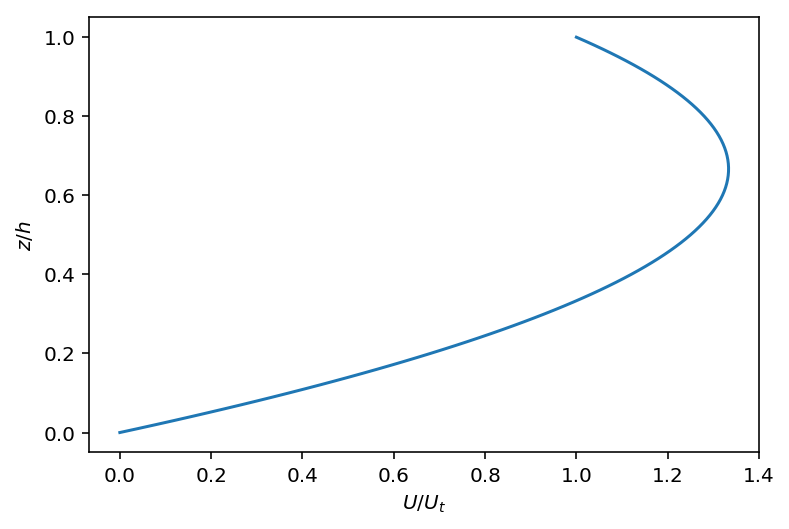

In [8]:
# solve the linear system [D2][u]=[r_neg]

u = scipy.linalg.solve(D2,r_neg)

# plot results 

fig, ax = plt.subplots()
ax.plot(u/Ut,z/h)
ax.set_xlabel('$U/U_t$')
ax.set_ylabel('$z/h$');

## Compare with the analytic solution

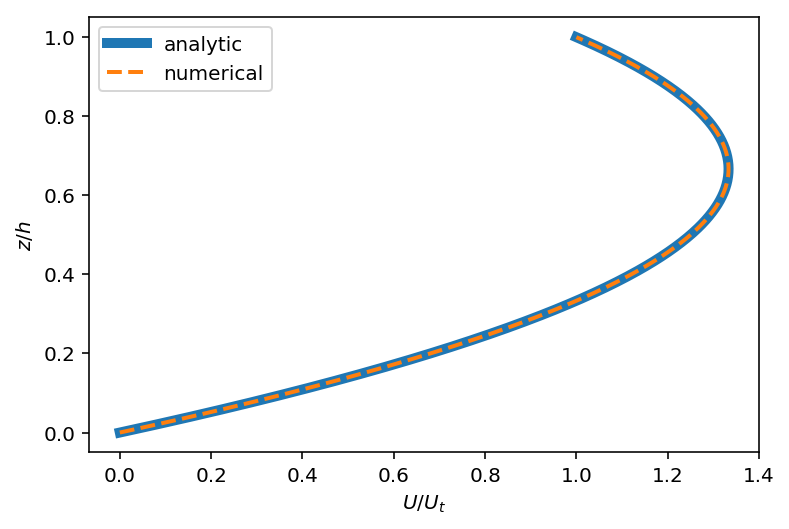

In [9]:
# analytic solution

n = 500
z_h = np.linspace(0,1,n)
u_Ut_analytic = P*z_h*(1-z_h)+z_h

fig, ax = plt.subplots()
ax.plot(u_Ut_analytic,z_h, linewidth=5.0, label='analytic')
ax.plot(u/Ut,z/h, linestyle='--', linewidth=2.0,label='numerical')
ax.set_xlabel('$U/U_t$')
ax.set_ylabel('$z/h$')
plt.legend(loc=2);

## Plot numerical solution over a range of $P$ values

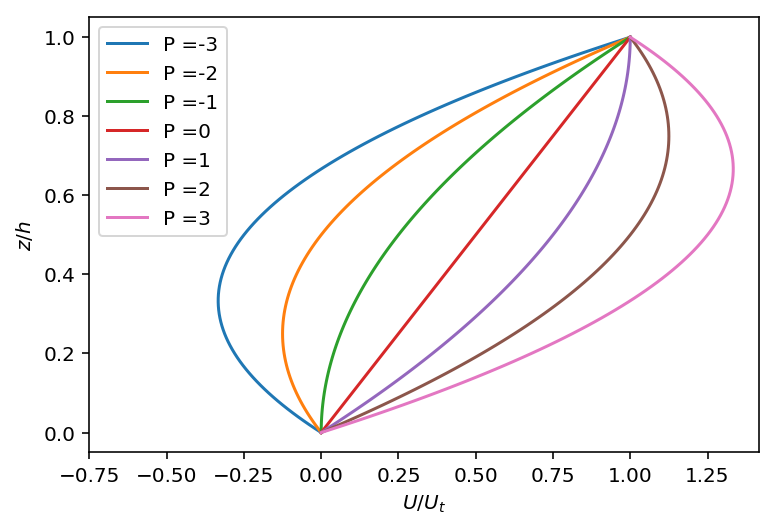

In [10]:
# look at numerical solution for a range of P values

P_values = np.array([-3,-2,-1,0,1,2,3]) # range of P values 

U_pvalues=np.zeros((len(P_values),N+1)) # a container to store the solution in

for i in range(0,len(P_values)):
    # define G and build the r array

    G = -2*mu*Ut*P_values[i]/h**2
    
    r=np.zeros(N+1)
    r[1:N]=-G/mu
    r[0]=Ub       # velocity at the bottom plate
    r[N]=Ut     # velocity at the top plate
    r_neg=-1*r.copy()

    # solve the linear system [D2][u]=[r_neg]

    u = scipy.linalg.solve(D2,r_neg)
    U_pvalues[i,:]=u.copy() # store the solution

# plot the data

fig, ax = plt.subplots()
for i in range(0,len(P_values)):
    ax.plot(U_pvalues[i,:]/Ut,z/h, label='P ='+str(P_values[i]))
ax.set_xlabel('$U/U_t$')
ax.set_ylabel('$z/h$')
ax.set_xlim(-0.75,)
plt.legend(loc=2);